1. Persoa que realiza o traballo: <u>Manuel Ramallo Blanco</u>



2. Función: F\(t\) = Ta\+\(T0\-Ta\)\*e^\(\-kt\)

Constantes definidas: k=0.4;T0=80;Ta=24

A función a estudar: F\(t\)=24\+\(80\-24\)_e^\(\-0.4_t\)\-37    no intervalo \[0,10\]



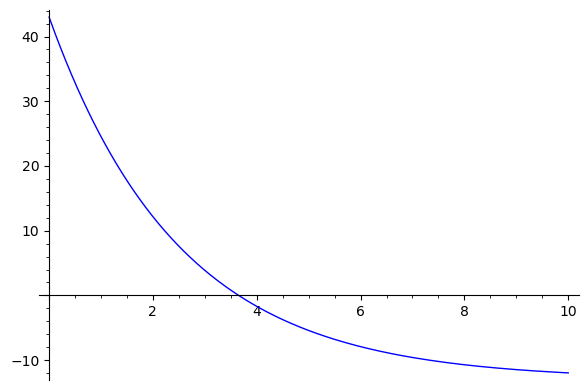

In [16]:
f(t)=24+(80-24)*e^(-0.4*t)-37
plot(f,0,10)

<span style='font-size:large'>**DICOTOMÍA**</span>

3. Cálculo da raíz por dicotomía



In [17]:
f(t)=24+(80-24)*e^(-0.4*t)-37; a=0; b=10; dicotomia(f,0,10)[:2]

(3.65100583318451, 44)

4. Gráfica de iterantes de dicotomía



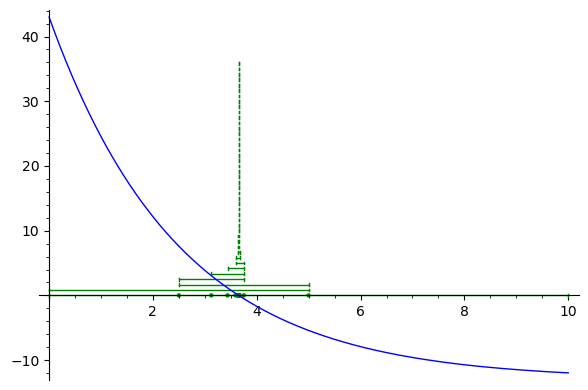

In [42]:
i,j,v,I = dicotomia(f, a, b)
debuxa_dicotomia(f, a, b, v, I)

5. Número máximo de iterantes



In [27]:
kmax = lambda a, b, xtol: ceil(log( (b-a)/xtol, 2))
kmax(a, b, 1e-12)

44

6. Xustificación do número de iterantes

O número de iterantes achado na práctica é coherente co achado na teoría \(44\)



<span style='font-size:large'>**NEWTON**</span>

7. Cálculo da raíz por Newton



In [25]:
newton(f,diff(f),0)

(3.65100583318403,
 7,
 [0.000000000000000,
  1.91964285714286,
  3.16889014292297,
  3.60736832676751,
  3.65062719304643,
  3.65100580451181,
  3.65100583318403])

8. Gráfica dos iterantes de Newton e as tanxentes do método



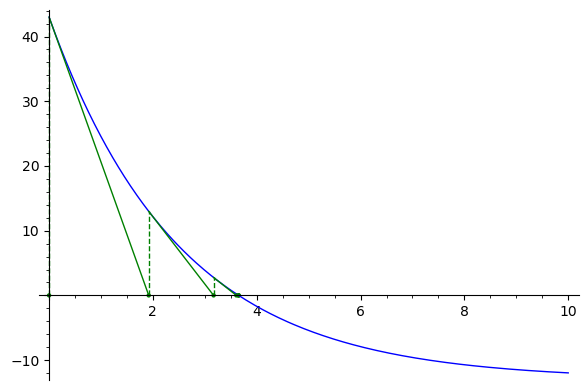

In [63]:
_,_,v = newton(f, diff(f), 0)
debuxa_newton(f, a, b, v)

9. **Gráfica das constantes de converxencia**



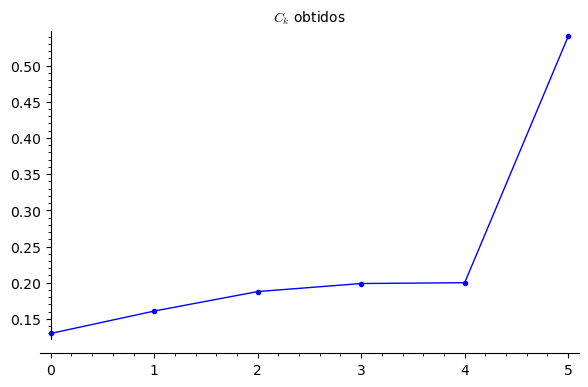

In [64]:
coef_newton(f, a, b, v)

10. **Xustificación de se nese caso hay converxencia**



Hai converxencia cuadrática porque o coeficiente de Newton converxe a 0.2 a medida que avanzan os iterantes. No último o valor do coeficiente alónxase  debido a que \(|alpha \- X\_k|^2\) é moi próximo a 0.


<span style='font-size:large'>ANEXO: Funcións de clase</span>

<span style='font-size:medium'>Método de dicotomía</span>



In [3]:
def dicotomia(f, a, b):
    xtol=1e-12
    rtol=1e-14
    """DICOTOMIA    Calculo de raices por dicotomia."""
    r = a
    k = 0
    v = []
    I = []
    # comprobacions previas
    if abs(f(a)).n() < rtol:
        r = a.n(); return r,k,v,I
    elif abs(f(b)).n() < rtol:
        r = b.n(); return r,k,v,I
    elif (f(a)*f(b)).n() > 0:
        raise RuntimeError('Extremos de igual signo.')
    # calculo iterativo
    while abs(b - a) > xtol:
        r = (a + b).n() / 2
        k = k + 1
        v.append(r)
        I.append((a,b))
        if abs(f(r)).n() < rtol:
            return r,k,v,I
        elif (f(a)*f(r)).n() < 0:
            b = r
        else:
            a = r
    return r,k,v,I

In [4]:
def debuxa_dicotomia(f, a, b, v, I):
    """DEBUXA_DICOTOMIA    Visualiza intervalos de dicotomía."""
    p = plot(f, a, b) + point(zip(v,[0]*len(v)), color='green')
    h = (p.ymax() - p.ymin())/(1.5*len(v))
    show(sum(line([(a,h*i),    (b,h*i)],     color='green') + \
             line([(a,h*i-h/4),(a,h*i+h/4)], color='green') + \
             line([(b,h*i-h/4),(b,h*i+h/4)], color='green')   \
             for i, (a,b) in enumerate(I)) + p, xmin=a, xmax=b)

<span style='font-size:medium'>Método de Newton</span>


In [5]:
def newton(f, df, x0, xtol=1e-12, rtol=1e-14, M=100, errorM=True):
    """NEWTON    Calculo de raices por Newton."""
    v = [x0.n()]
    for k in range(M):
        dfx = df(v[k]).n()
        if abs(dfx) < rtol:
            raise RuntimeError('Derivada nula.')
        r = (v[k] - f(v[k]) / dfx).n()
        v.append(r)
        # test de parada
        if abs(r-v[k]) < xtol or abs(f(r)).n() < rtol:
            return r, len(v), v
    #if errorM: raise RuntimeError('Excedido numero maximo de iteracions.')
    errorM=False
    return r,len(v),v

In [6]:
def debuxa_newton(f, a, b, v):
    """DEBUXA_NEWTON    Visualiza tanxentes do metodo de Newton."""
    show(plot(f, a, b) + point(zip(v,[0]*len(v)), color='green') + \
    sum(line([(v[i],0),(v[i],f(v[i]))], color='green', linestyle='--') for i in range(len(v))) + \
    sum(line([(v[i-1],f(v[i-1])), (v[i],0)], color='green') for i in range(1,len(v))), xmin=a, xmax=b)

In [7]:
def coef_newton(f, a, b, v):
    """COEF_NEWTON    Calcula os coeficientes de converxencia de Newton."""
    alpha = find_root(f, a, b, xtol=9.e-16, rtol=9.e-16) #aproximamos "ao máximo" a raíz
    pts = []
    for k in range(len(v)-1):
        if (alpha - v[k])^2 > RDF.epsilon():
            pts.append( (k, abs(alpha - v[k+1]) / (alpha - v[k])^2 ) )
    return line(pts, marker = '.', title='$C_k$ obtidos')

# Evaluación persona anterior:
Para que a corrección se considere válida, debes indicar os apartados nos que divides a
corrección (por exemplo, presentación, dicotomía, Newton), a nota máxima de cada
apartado e as razóns polas que lle asignaches a nota en cada un deles. A nota debe estar
nunha escala de 0 a 0,6 puntos.

Vou dividir a corrección en 3 apartados, que son os que siguen:
1. Presentación (máx 0.2p)
2. Dicotomía:(máx 0.2p)
3. Newton: (máx 0.2p)

## Puntuación por apartado:
### Presentación:
- Declarou a funcíon de forma correcta, cos parámetros especificados na función.
- Ademáis, a gráfica obtida é a esperada.

**Puntuación obtida: 0.2**

### Dicotomía:
- Ó cálculo da raíz por dicotomía está realizado correctamente. O resultado é o esperado, incluso con máis precisión da posiblemente requerida (Adxudícolle igualmente toda a puntuación).
- A gráfica dos iterantes de dicotomía é correcta.
- Tanto o cálculo do número máximo de iterantes coma a xustificación son correctos.

**Puntuación obtida: 0.2**

### Newton:
- A función para o cálculo da ráiz por Newton é a esperada e o resultado obtido é correcto.
- Cabe destacar que non se limitou a resposta solo ós dous primeiros elementos do resultado (aproximación da raíz e número de iteracións),senón que mostraronse tamén os valores do vector v, o que conten os resultados das diferentes iteracións. Por isto, **substraénse 0.03 puntos** do cómputo da puntuación do apartado de Newton.
- A gráfica dos iterantes e as tanxentes é correcta.
- A gráfica das constantes de converxencia e a xustificación son correctas. Extrañoume nunha primeira instancia que o valor en 5 dispararase, pero finalmente é devido á limitación do valor epsilon dos flotantes, o que impide que se faga o cálculo de forma máis precisa.

**Puntuación obtida: 0.17**

## Puntuación Final: **0.57**